# Definição inicial do campo vetorial

Define-se o campo como $\vec v = 0 \hat i + x(x-d) \hat j$

(2.0, 2.5)

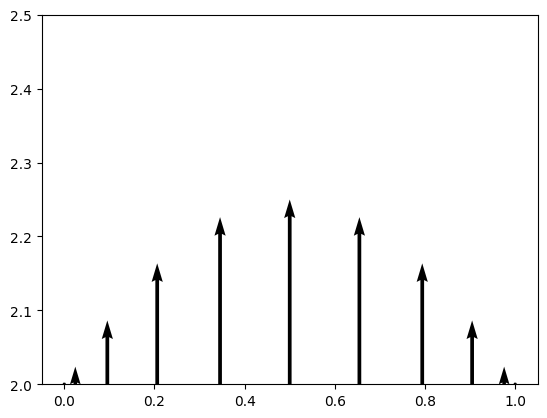

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # Necessário para 3D

diametro = 1
altura = 4
nr_pontos = 11
theta = np.linspace(0, np.pi, nr_pontos)


x = diametro/2 * np.cos(theta) + diametro/2
y = np.linspace(0, altura, int(nr_pontos/3))

vx = 0 * x
vy = -x*(x-diametro)

plt.quiver(x, altura/2, vx, vy, scale_units='xy', angles='xy', scale=1)
plt.ylim(2,2.5)

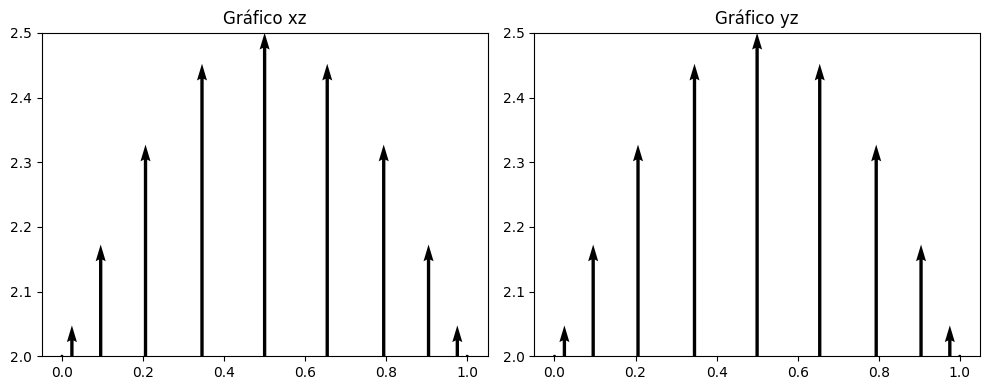

In [44]:
diametro = 1
nr_pontos = 11
altura = 4

x = diametro/2 * np.cos(theta) + diametro/2
y = x = diametro/2 * np.cos(theta) + diametro/2
z = np.linspace(0, altura, int(nr_pontos/3))

vx = 0 * x
vy = 0 * x
vz = -y*(x-diametro)-x*(x-diametro)


fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # 1 linha, 2 colunas
axes[0].quiver(x, altura/2, vx, vz, scale_units='xy', angles='xy', scale=1)
axes[0].set_ylim(2, 2.5)
axes[0].set_title("Gráfico xz")
axes[1].quiver(y, altura/2, vx, vz, scale_units='xy', angles='xy', scale=1)
axes[1].set_ylim(2, 2.5)
axes[1].set_title("Gráfico yz")
plt.tight_layout()
plt.show()

In [56]:
import numpy as np
import plotly.graph_objects as go

diametro = 1
altura = 4
nr_pontos = 61

# Use sin no Y para formar um semicírculo no plano XY
theta = np.linspace(0, 2*np.pi, nr_pontos, endpoint=True)
x = (diametro/2) * np.cos(theta) + diametro/2
y = (diametro/2) * np.sin(theta) + diametro/2

# Use mais amostras em z (ajuste conforme necessário)
z = np.linspace(0, altura, 3)

# Grid 3D
X, Y, Z = np.meshgrid(x, y, z, indexing='xy')

# Vector field (only W nonzero)
U = np.zeros_like(X)  # keep names without accents; comments in English
V = np.zeros_like(Y)
W = -X * (X - diametro) - Y * (Y - diametro)

# Scatter of points
scatter = go.Scatter3d(
    x=X.ravel(), y=Y.ravel(), z=Z.ravel(),
    mode='markers', marker=dict(size=3, color='blue'),
    name='Pontos'
)

# Cones (quiver 3D)
cones = go.Cone(
    x=X.ravel(), y=Y.ravel(), z=Z.ravel(),
    u=U.ravel(), v=V.ravel(), w=W.ravel(),
    sizemode='absolute',
    sizeref=0.25,          # tune arrow size
    anchor='tail',
    colorscale='Viridis',
    showscale=True,
    name='Campo vetorial'
)

layout = go.Layout(
    scene=dict(
        xaxis_title='X', yaxis_title='Y', zaxis_title='Z',
        aspectmode='cube'
    ),
    width=1000, height=800
)

fig = go.Figure(data=[scatter, cones], layout=layout)
fig.show()


Reresenta-se o módulo do rotacional.